# TP2 · Predicción de la tasa de adopción de IA

**Pregunta:** ¿Qué tasa continua de adopción de IA puede estimarse para una empresa y trimestre a partir de país, industria, cantidad de empleados, ingresos, antigüedad y año?

La variable objetivo es `ai_adoption_rate` (0–100). La prueba se separa por `company_id` para evaluar empresas nunca vistas; la validación de Ridge también agrupa por empresa. Se comparan una línea base y tres regresores. Todas las transformaciones se ajustan dentro del pipeline.

In [1]:
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import normaltest
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, GridSearchCV, cross_validate, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

SEMILLA = 2026
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLOR_BASE, COLOR_LINEA = "#2b5c8f", "#d95f02"

def encontrar_proyecto():
    ubicacion = Path.cwd().resolve()
    for carpeta in (ubicacion, *ubicacion.parents):
        proyecto = carpeta if carpeta.name == "proyecto_equipo" else carpeta / "proyecto_equipo"
        if (proyecto / "notebooks").is_dir():
            return proyecto
    raise FileNotFoundError("No se encontró proyecto_equipo/notebooks")

PROYECTO = encontrar_proyecto()
RUTA_PARQUET = PROYECTO / "datos" / "derivados" / "ai_company_adoption_limpio.parquet"
if not RUTA_PARQUET.exists():
    raise FileNotFoundError("Ejecutá antes 02_limpieza_ai.ipynb para generar el Parquet limpio")
SALIDAS = PROYECTO / "salidas"
SALIDAS.mkdir(parents=True, exist_ok=True)
df = pd.read_parquet(RUTA_PARQUET)
assert df.shape == (150_000, 43), f"Dimensiones inesperadas: {df.shape}"
print(f"Dataset: {len(df):,} filas | {df['company_id'].nunique():,} empresas | datos derivados del proyecto")

Dataset: 150,000 filas | 10,000 empresas | datos derivados del proyecto


In [2]:
# Objetivo continuo: tasa de adopción de IA, expresada entre 0 y 100.
objetivo = "ai_adoption_rate"
columnas_categoricas = ["country", "industry"]
columnas_log = ["num_employees", "annual_revenue_usd_millions"]
columnas_escaladas = ["company_age", "survey_year"]
predictores = columnas_log + columnas_escaladas + columnas_categoricas

# Excluimos el identificador y las variables derivadas del objetivo o medidas al mismo tiempo
# que podrían no estar disponibles al estimar adopción (incluida ai_adoption_stage).
X = df[predictores].copy()
y = pd.to_numeric(df[objetivo], errors="raise").astype(float)
grupos = df["company_id"].astype("string")

# Hold-out agrupado: las filas de cada empresa quedan juntas.
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEMILLA)
train_idx, test_idx = next(gss.split(X, y, groups=grupos))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
grupos_train, grupos_test = grupos.iloc[train_idx], grupos.iloc[test_idx]
assert set(grupos_train).isdisjoint(set(grupos_test))
print(f"Entrenamiento: {len(X_train):,} filas / {grupos_train.nunique():,} empresas")
print(f"Prueba: {len(X_test):,} filas / {grupos_test.nunique():,} empresas; empresas compartidas: 0")

Entrenamiento: 119,969 filas / 8,000 empresas
Prueba: 30,031 filas / 2,000 empresas; empresas compartidas: 0


In [3]:
# Cada modelo recibe su propio preprocesador para evitar estado compartido entre pipelines.
def crear_preprocesador():
    preparador_log = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("escalar", StandardScaler()),
    ])
    preparador_escalado = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
    ])
    preparador_categorico = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num_log", preparador_log, columnas_log),
        ("num_std", preparador_escalado, columnas_escaladas),
        ("cat", preparador_categorico, columnas_categoricas),
    ], remainder="drop")

In [4]:
# La línea base es la media. Ridge ajusta alpha con GroupKFold; el conjunto test queda intacto.
pipe_dummy = Pipeline([("modelo", DummyRegressor(strategy="mean"))])
cv_agrupado = GroupKFold(n_splits=5)
grilla_alpha = [0.001, 0.01, 0.1, 1, 10, 25, 50, 100, 200, 350, 500, 1_000, 2_500, 5_000, 10_000]
pipe_ridge = Pipeline([
    ("prepro", crear_preprocesador()),
    ("modelo", Ridge()),
])
grid_ridge = GridSearchCV(
    pipe_ridge,
    param_grid={"modelo__alpha": grilla_alpha},
    cv=cv_agrupado,
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    return_train_score=True,
    refit=True,
)
grid_ridge.fit(X_train, y_train, groups=grupos_train)
mejor_ridge = grid_ridge.best_estimator_
print(f"Mejor alpha Ridge: {grid_ridge.best_params_['modelo__alpha']}")
print(f"RMSE medio de Ridge en GroupKFold: {-grid_ridge.best_score_:.3f} puntos")

# El árbol limita profundidad y exige hojas de 50 filas para evitar reglas muy específicas.
pipe_tree = Pipeline([
    ("prepro", crear_preprocesador()),
    ("modelo", DecisionTreeRegressor(max_depth=6, min_samples_leaf=50, random_state=SEMILLA)),
])
# El bosque usa 100 árboles para estabilizar el ensamble; profundidad 10 y hojas de 20
# contienen la varianza y el costo computacional. Se mantienen fijos para comparar familias.
pipe_rf = Pipeline([
    ("prepro", crear_preprocesador()),
    ("modelo", RandomForestRegressor(
        n_estimators=100, max_depth=10, min_samples_leaf=20,
        random_state=SEMILLA, n_jobs=1,
    )),
])

# GroupKFold estima media y desvío en todos los modelos sobre empresas no vistas en cada fold.
# Ridge ya se evaluó con la misma partición dentro de GridSearchCV; sus scores por fold se recuperan
# del alpha seleccionado para que la tabla cubra también esa búsqueda.
scoring_reg = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}
cv_estimadores = {
    "Baseline (media)": pipe_dummy,
    "Ridge": mejor_ridge,
    "Árbol de decisión": pipe_tree,
    "Random Forest": pipe_rf,
}
resultados_cv = {}
for nombre in ["Baseline (media)", "Árbol de decisión", "Random Forest"]:
    resultados_cv[nombre] = cross_validate(
        cv_estimadores[nombre], X_train, y_train, groups=grupos_train,
        cv=cv_agrupado, scoring=scoring_reg, return_train_score=True, n_jobs=1,
    )
idx_alpha = grid_ridge.best_index_
folds = cv_agrupado.get_n_splits(X_train, y_train, grupos_train)
resultados_cv["Ridge"] = {
    "test_RMSE": np.array([grid_ridge.cv_results_[f"split{i}_test_score"][idx_alpha] for i in range(folds)]),
    "train_RMSE": np.array([grid_ridge.cv_results_[f"split{i}_train_score"][idx_alpha] for i in range(folds)]),
}
# GridSearchCV no devuelve MAE ni R²; se estiman para Ridge con cross_validate y alpha fijo elegido.
cv_ridge_fijo = cross_validate(
    mejor_ridge, X_train, y_train, groups=grupos_train, cv=cv_agrupado,
    scoring=scoring_reg, return_train_score=True, n_jobs=1,
)
resultados_cv["Ridge"].update({k: cv_ridge_fijo[k] for k in ["test_MAE", "train_MAE", "test_R2", "train_R2"]})
# Completar las métricas de las demás familias y consolidar media ± desvío estándar.
filas_cv = []
for nombre, r in resultados_cv.items():
    if nombre != "Ridge":
        # Convertir el signo negativo de los scorers de error a unidades positivas.
        test_rmse, train_rmse = -r["test_RMSE"], -r["train_RMSE"]
        test_mae, train_mae = -r["test_MAE"], -r["train_MAE"]
        test_r2, train_r2 = r["test_R2"], r["train_R2"]
    else:
        test_rmse, train_rmse = -r["test_RMSE"], -r["train_RMSE"]
        test_mae, train_mae = -r["test_MAE"], -r["train_MAE"]
        test_r2, train_r2 = r["test_R2"], r["train_R2"]
    filas_cv.append({
        "Modelo": nombre,
        "RMSE CV (media ± DE)": f"{test_rmse.mean():.3f} ± {test_rmse.std(ddof=1):.3f}",
        "MAE CV (media ± DE)": f"{test_mae.mean():.3f} ± {test_mae.std(ddof=1):.3f}",
        "R² CV (media ± DE)": f"{test_r2.mean():.3f} ± {test_r2.std(ddof=1):.3f}",
        "RMSE train CV (media)": round(train_rmse.mean(), 3),
        "RMSE validación CV (media)": round(test_rmse.mean(), 3),
        "Brecha RMSE CV": round(test_rmse.mean() - train_rmse.mean(), 3),
        "RMSE CV media numérica": test_rmse.mean(),
    })
df_cv_modelos = pd.DataFrame(filas_cv).sort_values("RMSE CV media numérica")
display(df_cv_modelos.drop(columns="RMSE CV media numérica"))
df_cv_modelos.drop(columns="RMSE CV media numérica").to_csv(SALIDAS / "validacion_cruzada_tp2.csv", index=False)

# Ajustar los modelos en todo train para comparar después, una sola vez, en el hold-out.
pipe_dummy.fit(X_train, y_train)
pipe_tree.fit(X_train, y_train)
pipe_rf.fit(X_train, y_train)
print("Modelos listos; la selección se hará por RMSE medio de CV, no mirando el test.")

Mejor alpha Ridge: 200
RMSE medio de Ridge en GroupKFold: 13.793 puntos


,Modelo,RMSE CV (media ± DE),MAE CV (media ± DE),R² CV (media ± DE),RMSE train CV (media),RMSE validación CV (media),Brecha RMSE CV
3,Ridge,13.793 ± 0.128,11.057 ± 0.098,0.098 ± 0.005,13.747,13.793,0.046
2,Random Forest,13.798 ± 0.126,11.061 ± 0.098,0.097 ± 0.008,13.282,13.798,0.516
1,Árbol de decisión,13.850 ± 0.139,11.098 ± 0.106,0.090 ± 0.008,13.693,13.850,0.157
0,Baseline (media),14.525 ± 0.111,11.639 ± 0.073,-0.001 ± 0.000,14.524,14.525,0.001


Modelos listos; la selección se hará por RMSE medio de CV, no mirando el test.


In [5]:
def evaluar_modelo(nombre, modelo, X_tr, y_tr, X_te, y_te):
    pred_tr = modelo.predict(X_tr)
    pred_te = modelo.predict(X_te)
    mse_tr, mse_te = mean_squared_error(y_tr, pred_tr), mean_squared_error(y_te, pred_te)
    p = len(modelo.named_steps["prepro"].get_feature_names_out()) if "prepro" in modelo.named_steps else 0
    def r2_ajustado(y_real, y_hat, p):
        n = len(y_real)
        if n <= p + 1:
            return np.nan
        r2 = r2_score(y_real, y_hat)
        return 1 - (1 - r2) * (n - 1) / (n - p - 1)
    def mape_sin_ceros(y_real, y_hat):
        y_real = np.asarray(y_real, dtype=float)
        y_hat = np.asarray(y_hat, dtype=float)
        mask = y_real != 0
        if not mask.any():
            return np.nan
        return np.mean(np.abs((y_real[mask] - y_hat[mask]) / y_real[mask])) * 100
    def wape(y_real, y_hat):
        denom = np.sum(np.abs(np.asarray(y_real, dtype=float)))
        return np.sum(np.abs(np.asarray(y_real, dtype=float) - np.asarray(y_hat, dtype=float))) / denom * 100 if denom else np.nan
    return {
        "Modelo": nombre,
        "Predictores transformados": p,
        "MSE (Train)": round(mse_tr, 3), "MSE (Test)": round(mse_te, 3),
        "RMSE (Train)": round(np.sqrt(mse_tr), 3), "RMSE (Test)": round(np.sqrt(mse_te), 3),
        "MAE (Train)": round(mean_absolute_error(y_tr, pred_tr), 3), "MAE (Test)": round(mean_absolute_error(y_te, pred_te), 3),
        "R² (Train)": round(r2_score(y_tr, pred_tr), 3), "R² (Test)": round(r2_score(y_te, pred_te), 3),
        "R² ajustado (Train)": round(r2_ajustado(y_tr, pred_tr, p), 3),
        "R² ajustado (Test)": round(r2_ajustado(y_te, pred_te, p), 3),
        "MAPE Train sin y=0 (%)": round(mape_sin_ceros(y_tr, pred_tr), 3),
        "MAPE Test sin y=0 (%)": round(mape_sin_ceros(y_te, pred_te), 3),
        "WAPE (Test, %)": round(wape(y_te, pred_te), 3),
        "Brecha RMSE": round(np.sqrt(mse_te) - np.sqrt(mse_tr), 3),
    }

modelos = [
    ("Baseline (media)", pipe_dummy), ("Ridge", mejor_ridge),
    ("Árbol de decisión", pipe_tree), ("Random Forest", pipe_rf),
]
df_comparativa = pd.DataFrame([
    evaluar_modelo(nombre, modelo, X_train, y_train, X_test, y_test)
    for nombre, modelo in modelos
])
# ai_adoption_rate contiene ceros: el MAPE se informa solo para y != 0 y se declara cuántos se excluyen.
ceros_train, ceros_test = int((y_train == 0).sum()), int((y_test == 0).sum())
print(f"Objetivo igual a cero: train={ceros_train:,}, test={ceros_test:,}; esas filas se excluyen del MAPE. WAPE se calcula sobre todas.")
display(df_comparativa)
df_comparativa.to_csv(SALIDAS / "tabla_comparativa_modelos_tp2.csv", index=False)

# Selección metodológica por validación cruzada; el test queda solo como evaluación final.
modelos_por_nombre = dict(modelos)
cv_no_baseline = df_cv_modelos[df_cv_modelos["Modelo"] != "Baseline (media)"]
mejor_nombre = cv_no_baseline.sort_values("RMSE CV media numérica").iloc[0]["Modelo"]
modelo_seleccionado = modelos_por_nombre[mejor_nombre]
print(f"Modelo seleccionado por menor RMSE medio de GroupKFold: {mejor_nombre}")

Objetivo igual a cero: train=705, test=191; esas filas se excluyen del MAPE. WAPE se calcula sobre todas.


,Modelo,Predictores transformados,MSE (Train),MSE (Test),RMSE (Train),RMSE (Test),MAE (Train),MAE (Test),R² (Train),R² (Test),R² ajustado (Train),R² ajustado (Test),MAPE Train sin y=0 (%),MAPE Test sin y=0 (%),"WAPE (Test, %)",Brecha RMSE
0,Baseline (media),0,210.946,213.863,14.524,14.624,11.638,11.716,0.000,-0.000,0.000,-0.000,76.155,71.375,32.277,0.100
1,Ridge,41,189.110,192.843,13.752,13.887,11.025,11.133,0.104,0.098,0.103,0.097,70.553,66.554,30.668,0.135
2,Árbol de decisión,41,188.064,191.435,13.714,13.836,10.993,11.074,0.108,0.105,0.108,0.104,70.693,66.807,30.506,0.122
3,Random Forest,41,178.014,190.855,13.342,13.815,10.691,11.067,0.156,0.107,0.156,0.106,68.977,66.521,30.487,0.473


Modelo seleccionado por menor RMSE medio de GroupKFold: Ridge


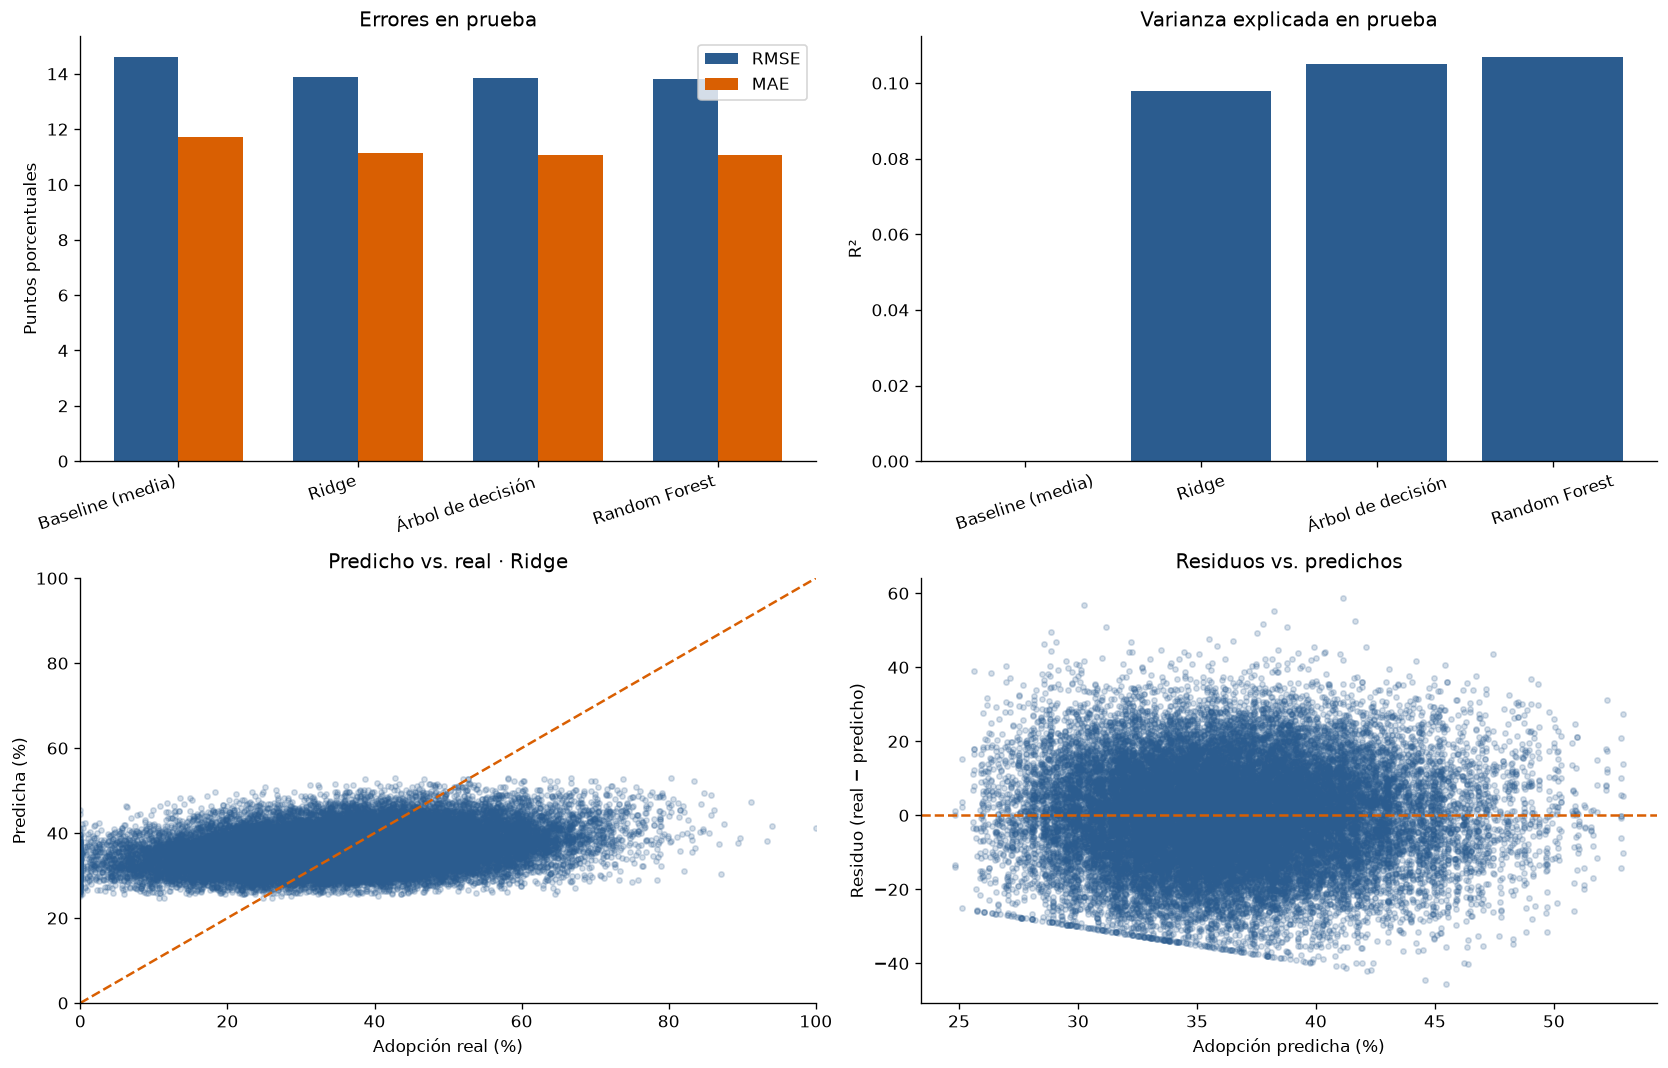

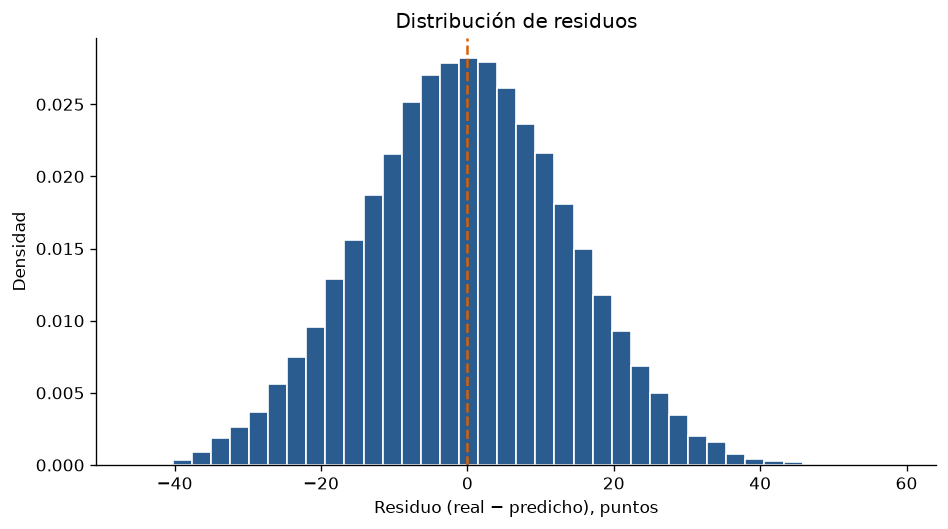

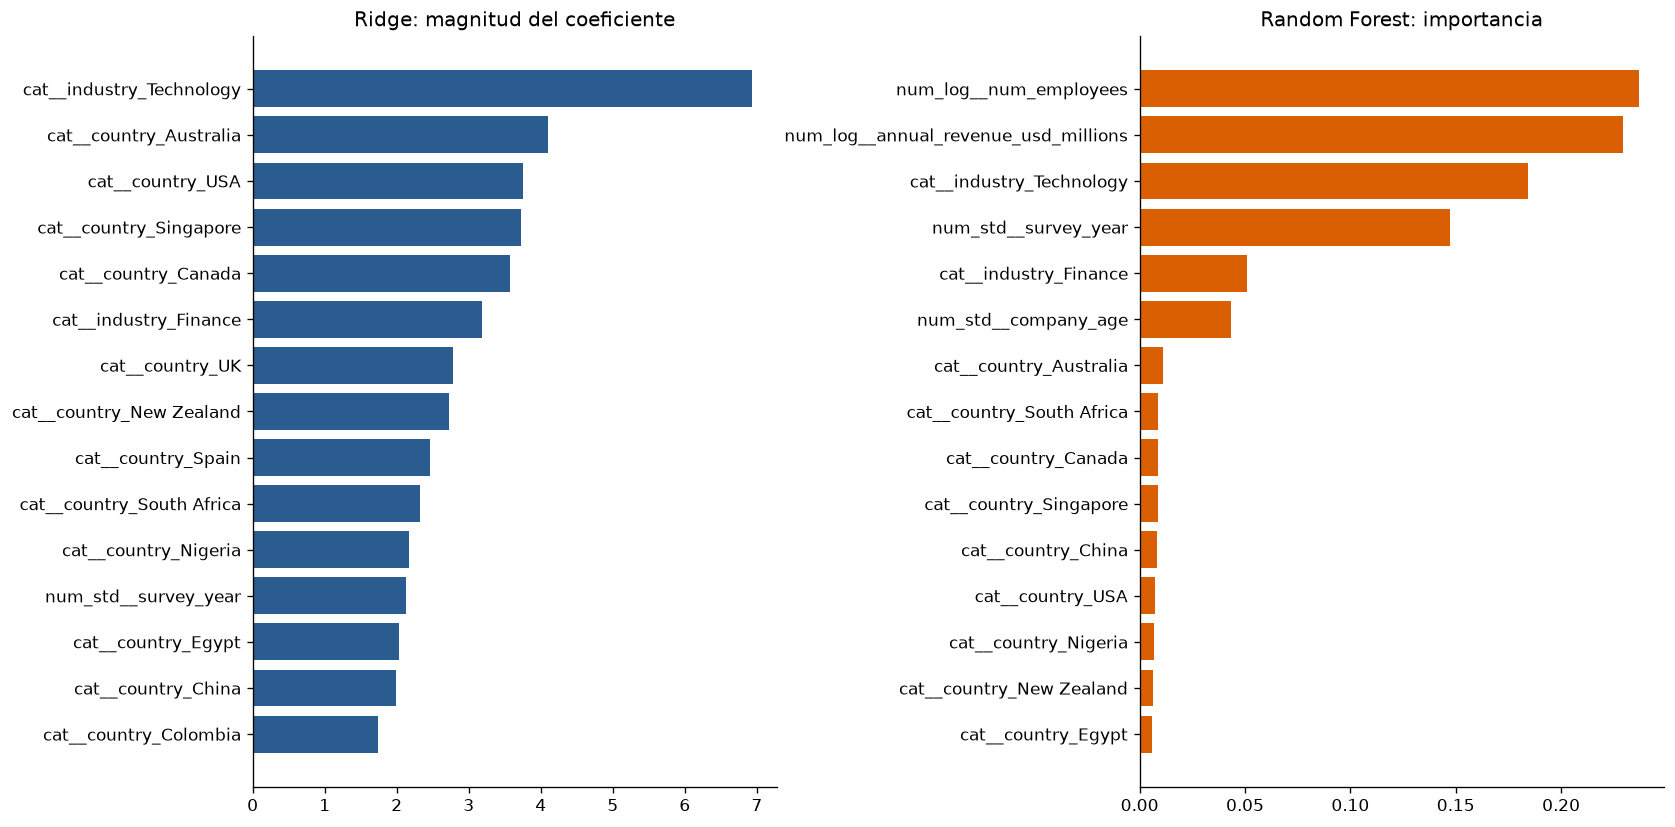

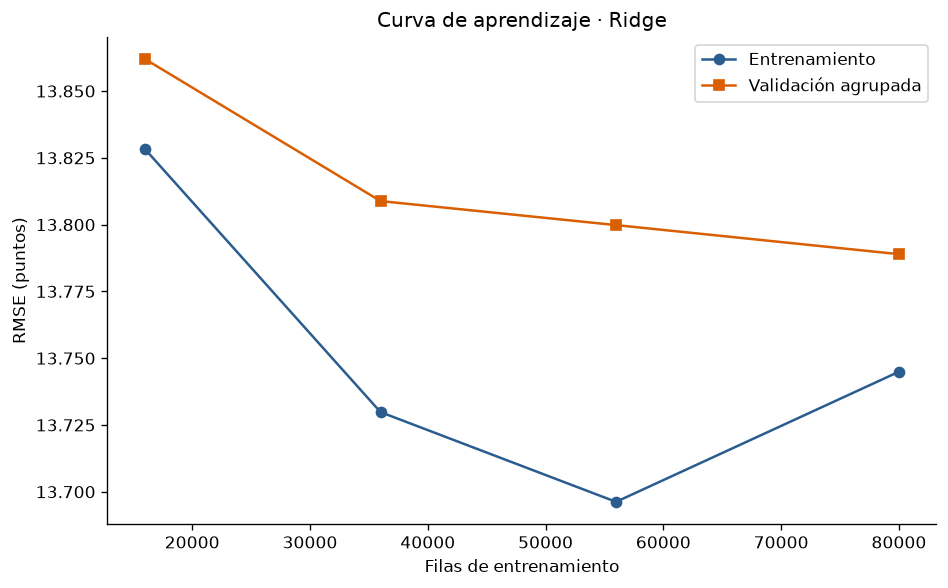

D’Agostino-Pearson en 5,000 residuos: estadístico=7.130, p=0.0283.
La prueba es diagnóstica y no determina por sí sola si el modelo es útil; con muchas observaciones puede detectar desvíos pequeños.


In [6]:
# Comparación gráfica de test y diagnósticos del modelo seleccionado por GroupKFold.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
x = np.arange(len(df_comparativa)); ancho = 0.36
axes[0, 0].bar(x-ancho/2, df_comparativa["RMSE (Test)"], ancho, label="RMSE", color=COLOR_BASE)
axes[0, 0].bar(x+ancho/2, df_comparativa["MAE (Test)"], ancho, label="MAE", color=COLOR_LINEA)
axes[0, 0].set(title="Errores en prueba", ylabel="Puntos porcentuales")
axes[0, 0].set_xticks(x, df_comparativa["Modelo"], rotation=18, ha="right"); axes[0, 0].legend()
axes[0, 1].bar(df_comparativa["Modelo"], df_comparativa["R² (Test)"], color=COLOR_BASE)
axes[0, 1].set(title="Varianza explicada en prueba", ylabel="R²"); axes[0, 1].tick_params(axis="x", rotation=18)

y_test_pred = modelo_seleccionado.predict(X_test)
residuos = y_test.to_numpy() - y_test_pred
axes[1, 0].scatter(y_test, y_test_pred, alpha=.2, color=COLOR_BASE, s=10)
axes[1, 0].plot([0, 100], [0, 100], "--", color=COLOR_LINEA)
axes[1, 0].set(xlabel="Adopción real (%)", ylabel="Predicha (%)", title=f"Predicho vs. real · {mejor_nombre}", xlim=(0,100), ylim=(0,100))
axes[1, 1].scatter(y_test_pred, residuos, alpha=.2, color=COLOR_BASE, s=10)
axes[1, 1].axhline(0, linestyle="--", color=COLOR_LINEA)
axes[1, 1].set(xlabel="Adopción predicha (%)", ylabel="Residuo (real − predicho)", title="Residuos vs. predichos")
plt.tight_layout(); plt.savefig(SALIDAS / "comparativas_y_diagnosticos_tp2.png", dpi=250, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(residuos, bins=40, color=COLOR_BASE, edgecolor="white", density=True)
ax.axvline(0, color=COLOR_LINEA, linestyle="--")
ax.set(xlabel="Residuo (real − predicho), puntos", ylabel="Densidad", title="Distribución de residuos")
plt.tight_layout(); plt.savefig(SALIDAS / "histograma_residuos_tp2.png", dpi=250, bbox_inches="tight"); plt.show()

# Importancia: magnitud absoluta de Ridge y reducción de impureza de Random Forest.
prep_rf = pipe_rf.named_steps["prepro"]
nombres_features = prep_rf.get_feature_names_out()
coef_ridge = mejor_ridge.named_steps["modelo"].coef_.ravel()
imp = pd.DataFrame({
    "Característica": nombres_features,
    "|Coeficiente Ridge|": np.abs(coef_ridge),
    "Importancia Random Forest": pipe_rf.named_steps["modelo"].feature_importances_,
})
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, col, titulo, color in [(axes[0], "|Coeficiente Ridge|", "Ridge: magnitud del coeficiente", COLOR_BASE),
                              (axes[1], "Importancia Random Forest", "Random Forest: importancia", COLOR_LINEA)]:
    top = imp.nlargest(15, col).sort_values(col)
    ax.barh(top["Característica"], top[col], color=color); ax.set_title(titulo)
plt.tight_layout(); plt.savefig(SALIDAS / "importancia_variables_tp2.png", dpi=250, bbox_inches="tight"); plt.show()

# Curva de aprendizaje por grupos para observar si más datos reducen sesgo o varianza.
tamanos, score_train, score_cv = learning_curve(
    modelo_seleccionado, X_train, y_train, groups=grupos_train,
    train_sizes=[0.2, 0.45, 0.7, 1.0], cv=GroupKFold(n_splits=3),
    scoring="neg_root_mean_squared_error", n_jobs=1,
)
rmse_train_curva, rmse_cv_curva = -score_train.mean(axis=1), -score_cv.mean(axis=1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(tamanos, rmse_train_curva, marker="o", label="Entrenamiento", color=COLOR_BASE)
ax.plot(tamanos, rmse_cv_curva, marker="s", label="Validación agrupada", color=COLOR_LINEA)
ax.set(xlabel="Filas de entrenamiento", ylabel="RMSE (puntos)", title=f"Curva de aprendizaje · {mejor_nombre}")
ax.legend(); plt.tight_layout(); plt.savefig(SALIDAS / "curva_aprendizaje_tp2.png", dpi=250, bbox_inches="tight"); plt.show()

# Diagnóstico opcional de normalidad: muestra de hasta 5.000 residuos; con n grande el test es sensible.
rng_residuos = np.random.default_rng(SEMILLA)
residuos_muestra = rng_residuos.choice(residuos, size=min(5_000, len(residuos)), replace=False)
estadistico_norm, p_norm = normaltest(residuos_muestra)
print(f"D’Agostino-Pearson en {len(residuos_muestra):,} residuos: estadístico={estadistico_norm:.3f}, p={p_norm:.3g}.")
print("La prueba es diagnóstica y no determina por sí sola si el modelo es útil; con muchas observaciones puede detectar desvíos pequeños.")

In [7]:
# Exportar el pipeline elegido y una pequeña muestra de empresas del test para la demo.
modelo_regresion_bundle = {
    "model": modelo_seleccionado,
    "features": predictores,
    "target": objetivo,
    "model_name": mejor_nombre,
    "category_options": {
        "country": sorted(df["country"].dropna().astype(str).unique().tolist()),
        "industry": sorted(df["industry"].dropna().astype(str).unique().tolist()),
    },
}
joblib.dump(modelo_regresion_bundle, SALIDAS / "modelo_regresion_tp2.joblib")
filas_test = df.iloc[test_idx].copy()
demo_reg = filas_test.sample(n=min(8, len(filas_test)), random_state=SEMILLA).copy()
demo_reg.insert(0, "demo_id", [f"REG-{i:02d}" for i in range(1, len(demo_reg)+1)])
demo_reg[["demo_id", "company_id", *predictores, objetivo]].to_csv(
    SALIDAS / "muestras_prueba_regresion.csv", index=False
)
print("Guardados: pipeline seleccionado y muestras de prueba de empresas no vistas.")

Guardados: pipeline seleccionado y muestras de prueba de empresas no vistas.


In [8]:
# Interpretación de esta ejecución, ligada a las métricas y diagnósticos observados.
from IPython.display import Markdown, display

fila_cv = df_cv_modelos[df_cv_modelos["Modelo"] == mejor_nombre].iloc[0]
fila_test = df_comparativa[df_comparativa["Modelo"] == mejor_nombre].iloc[0]
base_test = df_comparativa[df_comparativa["Modelo"] == "Baseline (media)"].iloc[0]
mejora_rmse = (base_test["RMSE (Test)"] - fila_test["RMSE (Test)"]) / base_test["RMSE (Test)"] * 100
brecha = df_comparativa.set_index("Modelo")["Brecha RMSE"]
mayor_brecha = brecha.idxmax()
texto = f"""### Lectura de resultados de regresión

- **Selección:** {mejor_nombre} tuvo el menor RMSE medio en GroupKFold ({fila_cv['RMSE CV (media ± DE)']}) y obtuvo RMSE {fila_test['RMSE (Test)']:.3f}, MAE {fila_test['MAE (Test)']:.3f} y R² {fila_test['R² (Test)']:.3f} en empresas reservadas. Frente a la línea base, su RMSE de test cambia {mejora_rmse:+.1f}%. El R² bajo indica que los predictores disponibles explican una parte limitada de la variación; la mejora no implica que el error sea pequeño para todos los usos.
- **Ajuste:** la mayor brecha RMSE train-test corresponde a {mayor_brecha} ({brecha[mayor_brecha]:.3f} puntos). Las brechas y la curva de aprendizaje ayudan a distinguir varianza de capacidad predictiva limitada. El gráfico de residuos vs. predichos permite buscar sesgo o dispersión no constante; el test de normalidad es complementario y sensible al tamaño de muestra.
- **Métricas porcentuales:** el objetivo tiene ceros (train={ceros_train:,}; test={ceros_test:,}); por eso el MAPE se calcula solo para observaciones no nulas y se acompaña con WAPE sobre todas las filas. No se debe interpretar el MAPE como si cubriera los casos con adopción cero.
- **Alcance:** el objetivo y predictores describen adopción de IA en este dataset observacional. Las asociaciones no establecen causalidad; la procedencia del dataset tampoco permite generalizar a todas las empresas.
"""
display(Markdown(texto))

### Lectura de resultados de regresión

- **Selección:** Ridge tuvo el menor RMSE medio en GroupKFold (13.793 ± 0.128) y obtuvo RMSE 13.887, MAE 11.133 y R² 0.098 en empresas reservadas. Frente a la línea base, su RMSE de test cambia +5.0%. El R² bajo indica que los predictores disponibles explican una parte limitada de la variación; la mejora no implica que el error sea pequeño para todos los usos.
- **Ajuste:** la mayor brecha RMSE train-test corresponde a Random Forest (0.473 puntos). Las brechas y la curva de aprendizaje ayudan a distinguir varianza de capacidad predictiva limitada. El gráfico de residuos vs. predichos permite buscar sesgo o dispersión no constante; el test de normalidad es complementario y sensible al tamaño de muestra.
- **Métricas porcentuales:** el objetivo tiene ceros (train=705; test=191); por eso el MAPE se calcula solo para observaciones no nulas y se acompaña con WAPE sobre todas las filas. No se debe interpretar el MAPE como si cubriera los casos con adopción cero.
- **Alcance:** el objetivo y predictores describen adopción de IA en este dataset observacional. Las asociaciones no establecen causalidad; la procedencia del dataset tampoco permite generalizar a todas las empresas.
